In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 15.1 — Embeddings, restrictions and projectors

Source: SMSA version 7.8 (2026-11-05), `smsa.pdf`. This notebook translates the named formulas; it does not replace their discussion in SMSA. Native DisCoPy figures below read **top to bottom**, whereas SMSA reads bottom to top. Tensor factors retain their left-to-right order. `f >> g` means $g\circ f$. Tensor arrays list input axes before output axes; a conventional column matrix is supplied transposed. Checks print computed objects and residuals and do not stop execution on a failed equality.

Graphical calculus 15.1.10, (15.7)–(15.11). To instantiate the direct-sum wire calculation, choose $W=\mathbb C^2$ split into its two coordinate lines. The example tests the linear-map identities underlying the representation decomposition; no particular Lie action is supplied. Each summand is one-dimensional and is mapped by the tensor functor to the tensor unit.

In [1]:
from discopy import symmetric, tensor
import numpy as np

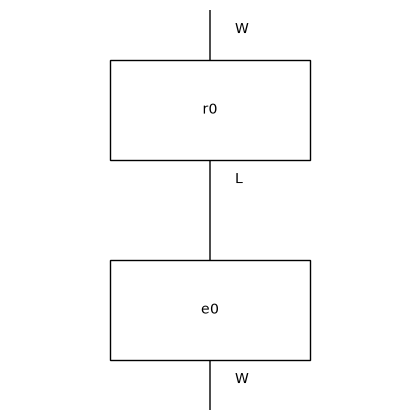

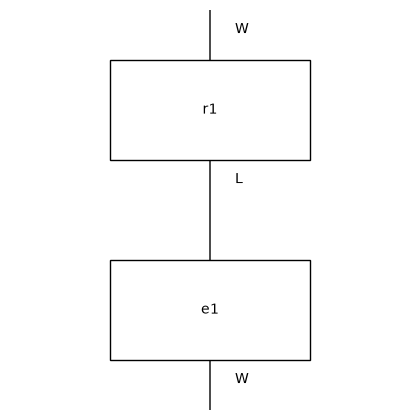

In [2]:
L, W = symmetric.Ty('L'), symmetric.Ty('W')
e0, e1 = symmetric.Box('e0',L,W), symmetric.Box('e1',L,W)
r0, r1 = symmetric.Box('r0',W,L), symmetric.Box('r1',W,L)
p0, p1 = r0 >> e0, r1 >> e1
p0.draw(figsize=(4,4))
p1.draw(figsize=(4,4))

In [3]:
F = tensor.Functor({L: tensor.Dim(1), W: tensor.Dim(2)}, {e0:[1,0],e1:[0,1],r0:[1,0],r1:[0,1]}, dom=symmetric.Category, dtype=int)
print('(15.8): r_p composed with e_q, rows p and columns q')
print([[F(e0 >> r0).array.tolist(), F(e1 >> r0).array.tolist()], [F(e0 >> r1).array.tolist(), F(e1 >> r1).array.tolist()]])
print('expected = [[1,0],[0,1]]')
print('p0 =', F(p0).array, '; p1 =', F(p1).array)
print('completeness residual =', (F(p0)+F(p1)).array-F(symmetric.Id(W)).array)
print('(15.9) p0 squared minus p0 =', F(p0 >> p0).array-F(p0).array)
print('(15.9) p1 squared minus p1 =', F(p1 >> p1).array-F(p1).array)

(15.8): r_p composed with e_q, rows p and columns q
[[1, 0], [0, 1]]
expected = [[1,0],[0,1]]
p0 = [[1 0]
 [0 0]] ; p1 = [[0 0]
 [0 1]]
completeness residual = [[0 0]
 [0 0]]
(15.9) p0 squared minus p0 = [[0 0]
 [0 0]]
(15.9) p1 squared minus p1 = [[0 0]
 [0 0]]
